Shape: (10205, 16)

Missing values:
 Tenure    1
dtype: int64

Duplicate rows: 0


C:\Users\subha\AppData\Local\Temp\ipykernel_19688\2756895954.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Churn', data=df, palette='Set2')


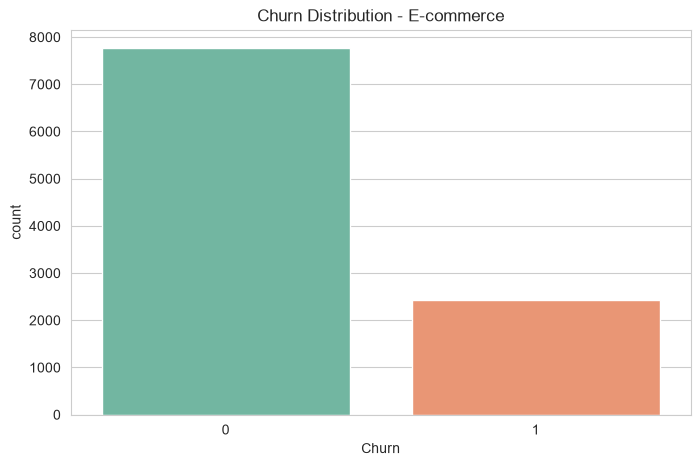

Churn
0    76.129348
1    23.870652
Name: proportion, dtype: float64


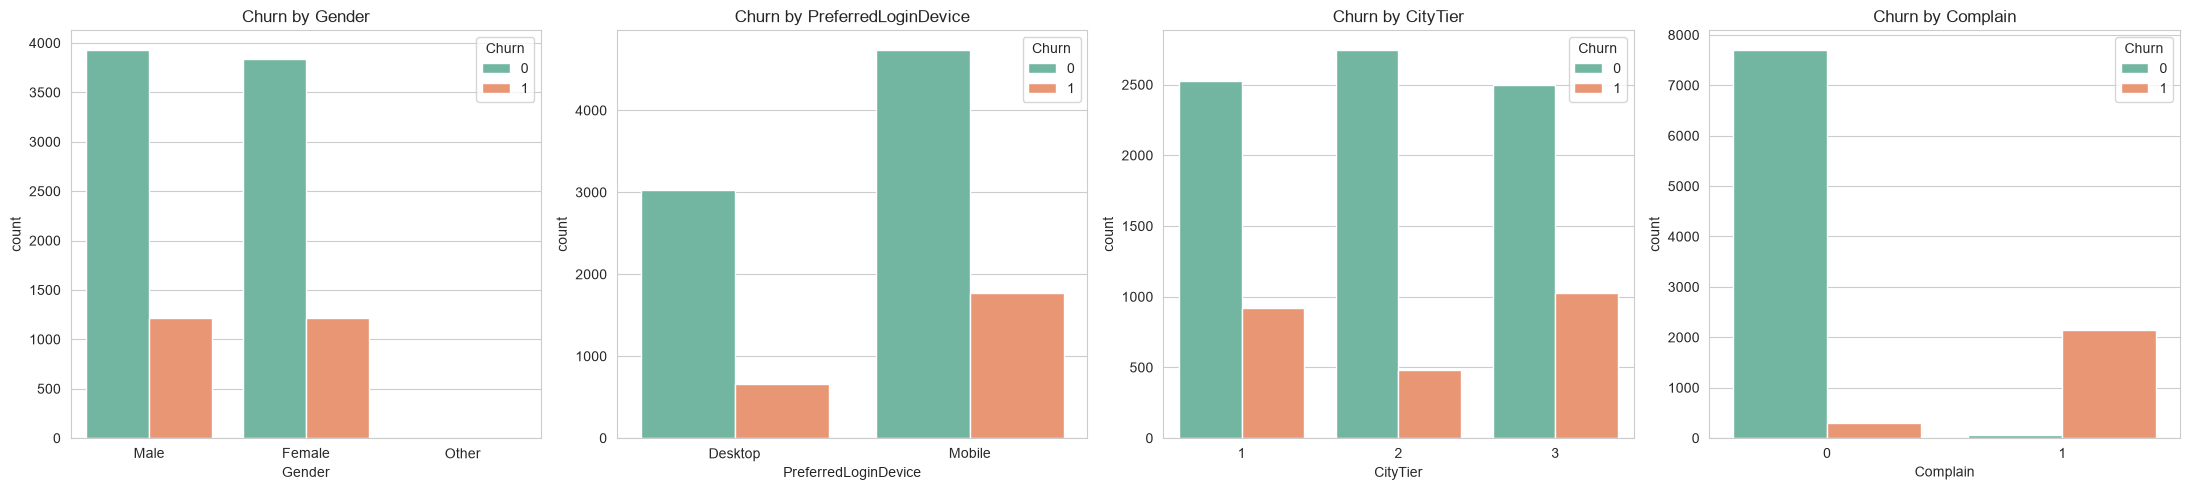

C:\Users\subha\AppData\Local\Temp\ipykernel_19688\2756895954.py:67: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Churn', y=col, data=df, ax=ax, palette='Set2')
C:\Users\subha\AppData\Local\Temp\ipykernel_19688\2756895954.py:67: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Churn', y=col, data=df, ax=ax, palette='Set2')
C:\Users\subha\AppData\Local\Temp\ipykernel_19688\2756895954.py:67: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Churn', y=col, data=df, ax=ax, palette='Set2')
C:\Users\subha\AppData\Local\Temp\ipykernel_19688\27568

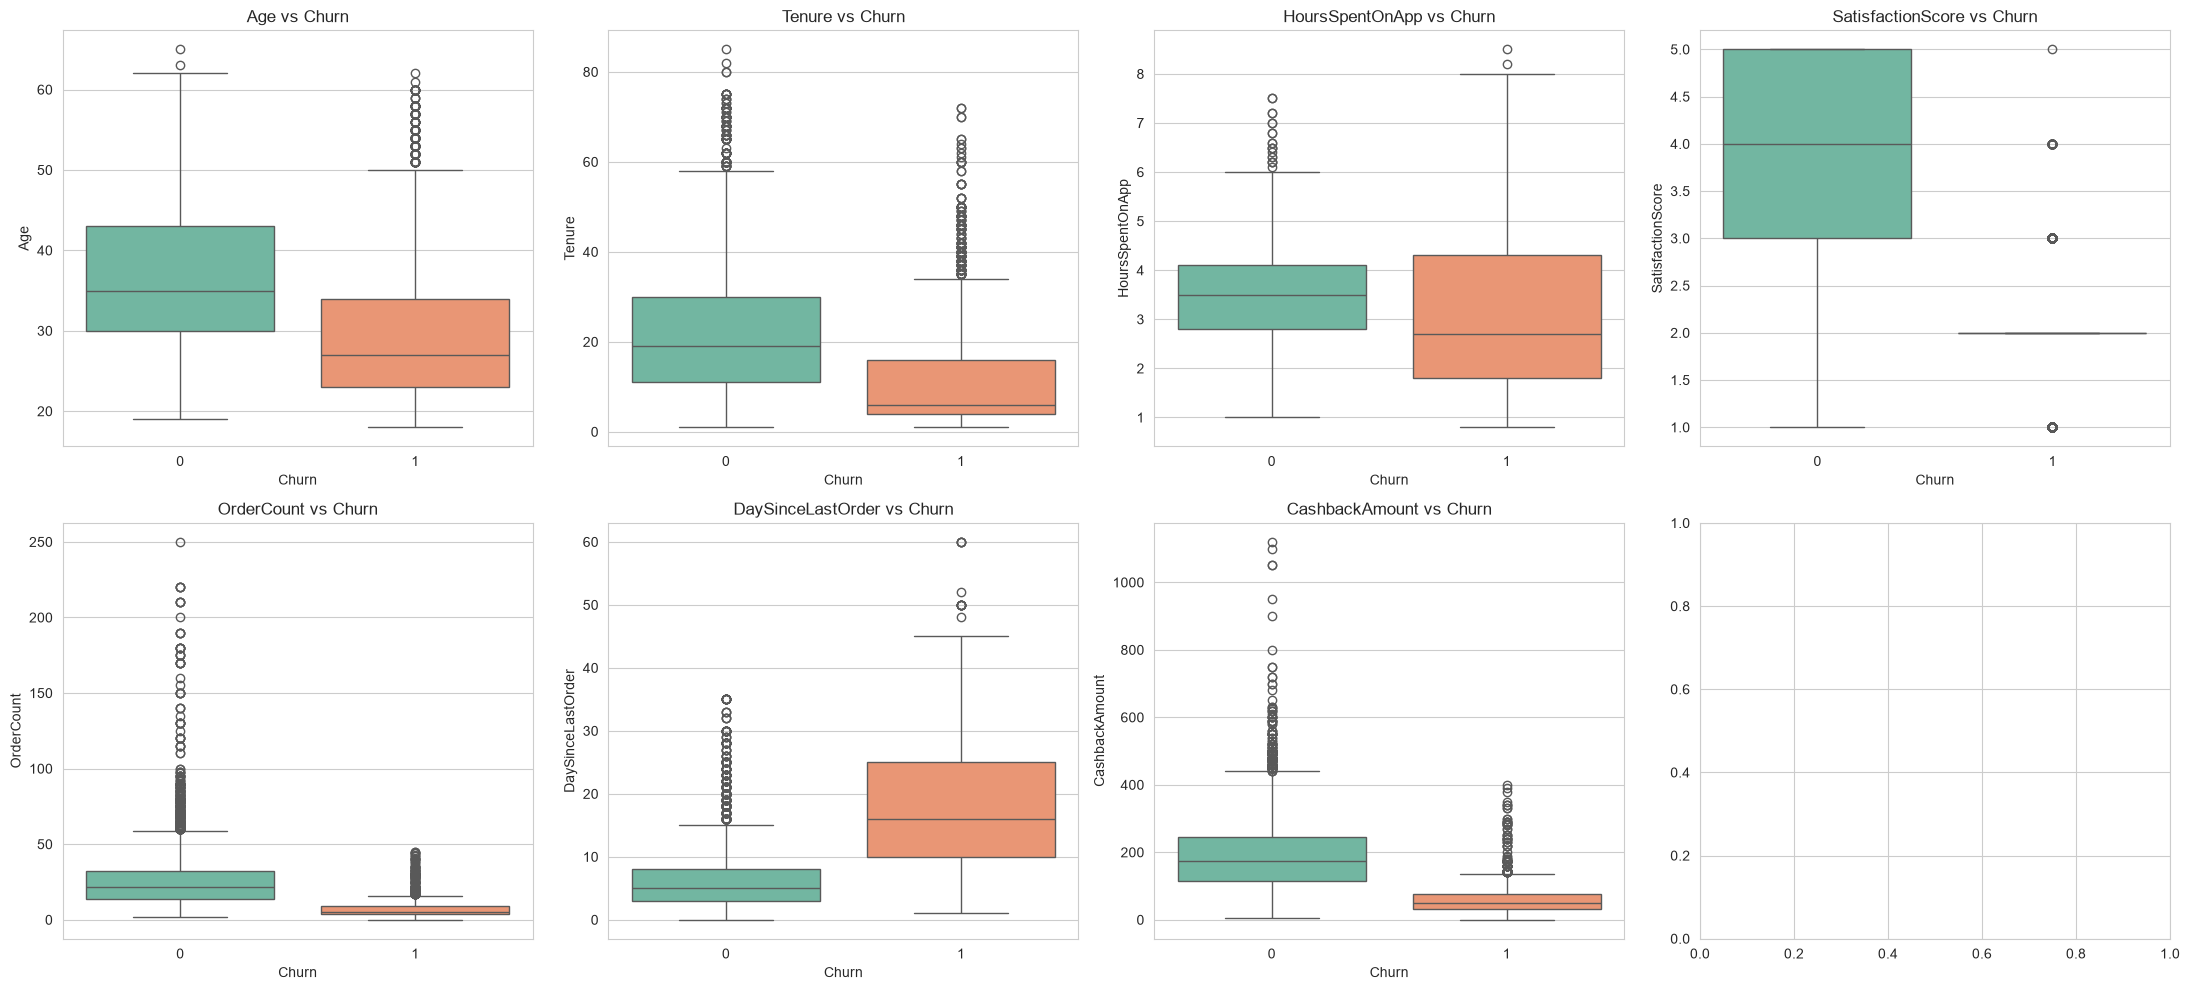

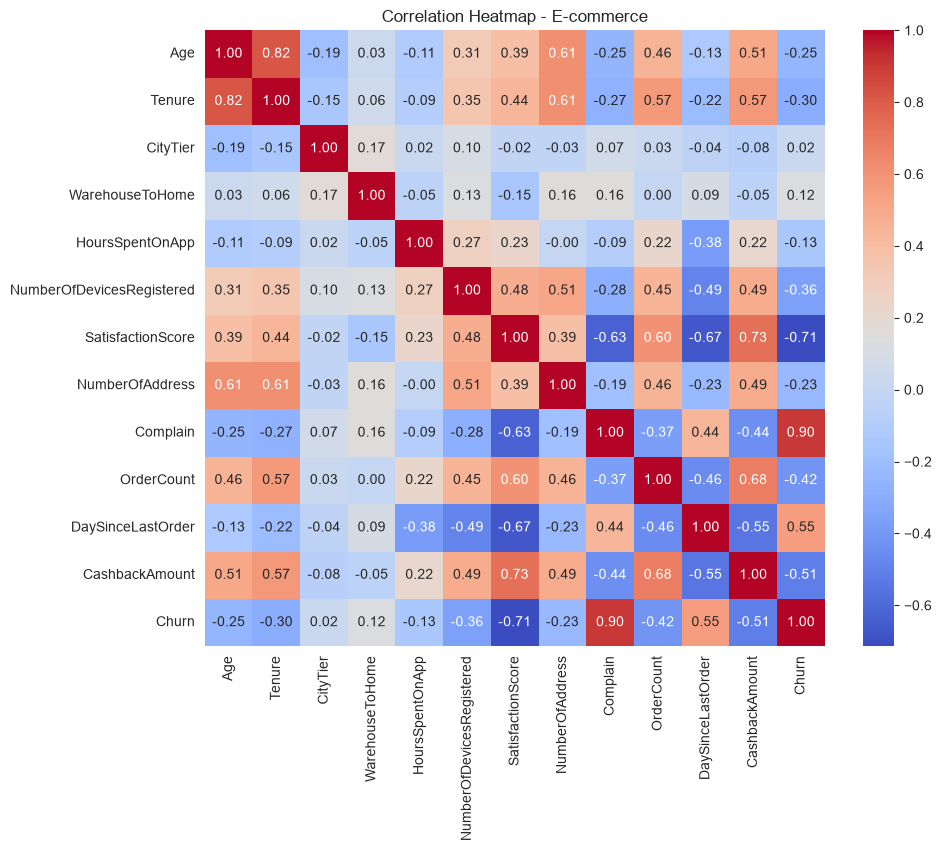

Gender : ['Female', 'Male', 'Other']
PreferredLoginDevice : ['Desktop', 'Mobile']
CityTier : [1, 2, 3]
SatisfactionScore : [1, 2, 3, 4, 5]
Complain : [0, 1]
Train shape: (8164, 14) | Test shape: (2041, 14)


C:\Users\subha\AppData\Local\Temp\ipykernel_19688\2756895954.py:89: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_feature_cols = X.select_dtypes(include=['object']).columns.tolist()


Decision Tree best params: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2}
Random Forest best params: {'max_depth': 15, 'min_samples_split': 2, 'n_estimators': 100}


C:\Users\subha\AppData\Roaming\Python\Python314\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM best params: {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}

--- Overfitting Check ---
Decision Tree: Train=0.999, Test=0.997, Gap=0.003 ✅ OK
Random Forest: Train=1.000, Test=1.000, Gap=0.000 ✅ OK
SVM: Train=0.996, Test=0.999, Gap=-0.002 ✅ OK

--- Test Set Evaluation ---

Decision Tree:
  Accuracy: 0.997 | Precision: 0.996 | Recall: 0.990 | F1: 0.993 | ROC-AUC: 0.995

Random Forest:
  Accuracy: 1.000 | Precision: 0.998 | Recall: 1.000 | F1: 0.999 | ROC-AUC: 1.000

SVM:
  Accuracy: 0.999 | Precision: 0.994 | Recall: 1.000 | F1: 0.997 | ROC-AUC: 1.000

            Model  Accuracy  Precision    Recall        F1   ROC-AUC
0  Decision Tree   0.99657   0.995868  0.989733  0.992791  0.994521
1  Random Forest   0.99951   0.997951  1.000000  0.998974  0.999998
2            SVM   0.99853   0.993878  1.000000  0.996929  0.999989


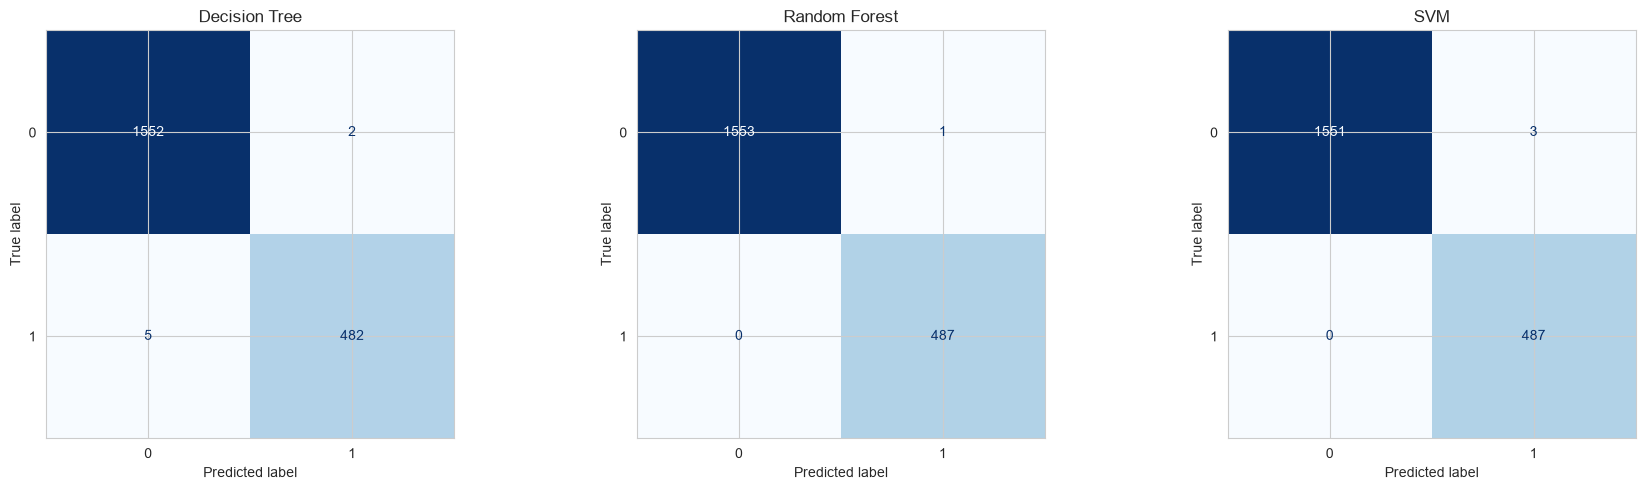

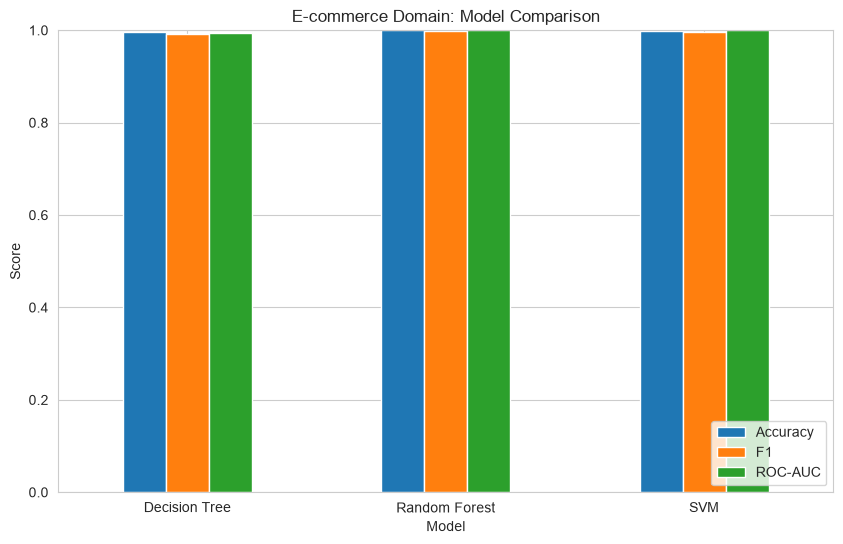


🏆 Best model: Random Forest
Saved: ecommerce_model.pkl, ecommerce_scaler.pkl, ecommerce_encoders.pkl


In [4]:
# ============================================================
# ECOMMERCE CHURN - FULL PIPELINE
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                               f1_score, roc_auc_score, confusion_matrix,
                               ConfusionMatrixDisplay)

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (8, 5)

# ============================================================
# STEP 1: Load and inspect
# ============================================================
df = pd.read_csv('../data/raw/ecommerce_churn_data.csv')
print("Shape:", df.shape)
print("\nMissing values:\n", df.isnull().sum()[df.isnull().sum() > 0])
print("\nDuplicate rows:", df.duplicated().sum())

# Drop identifier
df = df.drop(columns=['CustomerID'])

# Fill any missing numeric values with median (safe default)
num_cols_all = df.select_dtypes(include=[np.number]).columns
df[num_cols_all] = df[num_cols_all].fillna(df[num_cols_all].median())

# ============================================================
# STEP 2: EDA - Target distribution
# ============================================================
plt.figure()
sns.countplot(x='Churn', data=df, palette='Set2')
plt.title('Churn Distribution - E-commerce')
plt.show()
print(df['Churn'].value_counts(normalize=True) * 100)

# ============================================================
# STEP 3: EDA - Categorical features vs churn
# ============================================================
cat_cols = ['Gender', 'PreferredLoginDevice', 'CityTier', 'Complain']

fig, axes = plt.subplots(1, 4, figsize=(22, 5))
for ax, col in zip(axes, cat_cols):
    sns.countplot(x=col, hue='Churn', data=df, ax=ax, palette='Set2')
    ax.set_title(f'Churn by {col}')
plt.tight_layout()
plt.show()

# ============================================================
# STEP 4: EDA - Numerical features vs churn
# ============================================================
num_cols = ['Age', 'Tenure', 'HoursSpentOnApp', 'SatisfactionScore',
            'OrderCount', 'DaySinceLastOrder', 'CashbackAmount']

fig, axes = plt.subplots(2, 4, figsize=(22, 10))
for ax, col in zip(axes.flatten(), num_cols):
    sns.boxplot(x='Churn', y=col, data=df, ax=ax, palette='Set2')
    ax.set_title(f'{col} vs Churn')
plt.tight_layout()
plt.show()

# ============================================================
# STEP 5: Correlation heatmap
# ============================================================
plt.figure(figsize=(10, 8))
corr = df.select_dtypes(include=[np.number]).corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap - E-commerce')
plt.show()
for col in ['Gender', 'PreferredLoginDevice', 'CityTier', 'SatisfactionScore', 'Complain']:
    print(col, ":", sorted(df[col].unique().tolist()))

# ============================================================
# STEP 6: Preprocessing
# ============================================================
X = df.drop(columns=['Churn'])
y = df['Churn']

cat_feature_cols = X.select_dtypes(include=['object']).columns.tolist()
encoders = {}
for col in cat_feature_cols:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col].astype(str))
    encoders[col] = le

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train shape:", X_train.shape, "| Test shape:", X_test.shape)

# ============================================================
# STEP 7: Train models with GridSearchCV
# ============================================================
results = {}

dt_params = {'max_depth': [4, 6, 8, 10], 'min_samples_split': [2, 5, 10], 'min_samples_leaf': [1, 2, 4]}
dt_grid = GridSearchCV(DecisionTreeClassifier(class_weight='balanced', random_state=42),
                        dt_params, cv=5, scoring='f1', n_jobs=-1)
dt_grid.fit(X_train_scaled, y_train)
results['Decision Tree'] = dt_grid.best_estimator_
print("Decision Tree best params:", dt_grid.best_params_)

rf_params = {'n_estimators': [100, 200], 'max_depth': [6, 10, 15], 'min_samples_split': [2, 5]}
rf_grid = GridSearchCV(RandomForestClassifier(class_weight='balanced', random_state=42),
                        rf_params, cv=5, scoring='f1', n_jobs=-1)
rf_grid.fit(X_train_scaled, y_train)
results['Random Forest'] = rf_grid.best_estimator_
print("Random Forest best params:", rf_grid.best_params_)

svm_params = {'C': [0.1, 1, 10], 'kernel': ['rbf', 'linear'], 'gamma': ['scale', 'auto']}
svm_grid = GridSearchCV(SVC(class_weight='balanced', probability=True, random_state=42),
                         svm_params, cv=5, scoring='f1', n_jobs=-1)
svm_grid.fit(X_train_scaled, y_train)
results['SVM'] = svm_grid.best_estimator_
print("SVM best params:", svm_grid.best_params_)

# ============================================================
# STEP 8: Overfitting check
# ============================================================
print("\n--- Overfitting Check ---")
for name, model in results.items():
    train_acc = accuracy_score(y_train, model.predict(X_train_scaled))
    test_acc = accuracy_score(y_test, model.predict(X_test_scaled))
    gap = train_acc - test_acc
    flag = "⚠️ possible overfitting" if gap > 0.10 else "✅ OK"
    print(f"{name}: Train={train_acc:.3f}, Test={test_acc:.3f}, Gap={gap:.3f} {flag}")

# ============================================================
# STEP 9: Evaluation metrics
# ============================================================
print("\n--- Test Set Evaluation ---")
metrics_summary = []
for name, model in results.items():
    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba)
    metrics_summary.append([name, acc, prec, rec, f1, auc])
    print(f"\n{name}:")
    print(f"  Accuracy: {acc:.3f} | Precision: {prec:.3f} | Recall: {rec:.3f} | F1: {f1:.3f} | ROC-AUC: {auc:.3f}")

metrics_df = pd.DataFrame(metrics_summary, columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC'])
print("\n", metrics_df)

# ============================================================
# STEP 10: Confusion matrices
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, model) in zip(axes, results.items()):
    y_pred = model.predict(X_test_scaled)
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

# ============================================================
# STEP 11: Model comparison chart
# ============================================================
metrics_df.set_index('Model')[['Accuracy', 'F1', 'ROC-AUC']].plot(kind='bar', figsize=(10, 6))
plt.title('E-commerce Domain: Model Comparison')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(loc='lower right')
plt.show()

# ============================================================
# STEP 12: Save best model
# ============================================================
best_model_name = metrics_df.loc[metrics_df['F1'].idxmax(), 'Model']
best_model = results[best_model_name]
print(f"\n🏆 Best model: {best_model_name}")

os.makedirs('../models', exist_ok=True)
joblib.dump(best_model, '../models/ecommerce_model.pkl')
joblib.dump(scaler, '../models/ecommerce_scaler.pkl')
joblib.dump(encoders, '../models/ecommerce_encoders.pkl')
print("Saved: ecommerce_model.pkl, ecommerce_scaler.pkl, ecommerce_encoders.pkl")

In [5]:
print(X.columns.tolist())

['Age', 'Gender', 'Tenure', 'PreferredLoginDevice', 'CityTier', 'WarehouseToHome', 'HoursSpentOnApp', 'NumberOfDevicesRegistered', 'SatisfactionScore', 'NumberOfAddress', 'Complain', 'OrderCount', 'DaySinceLastOrder', 'CashbackAmount']


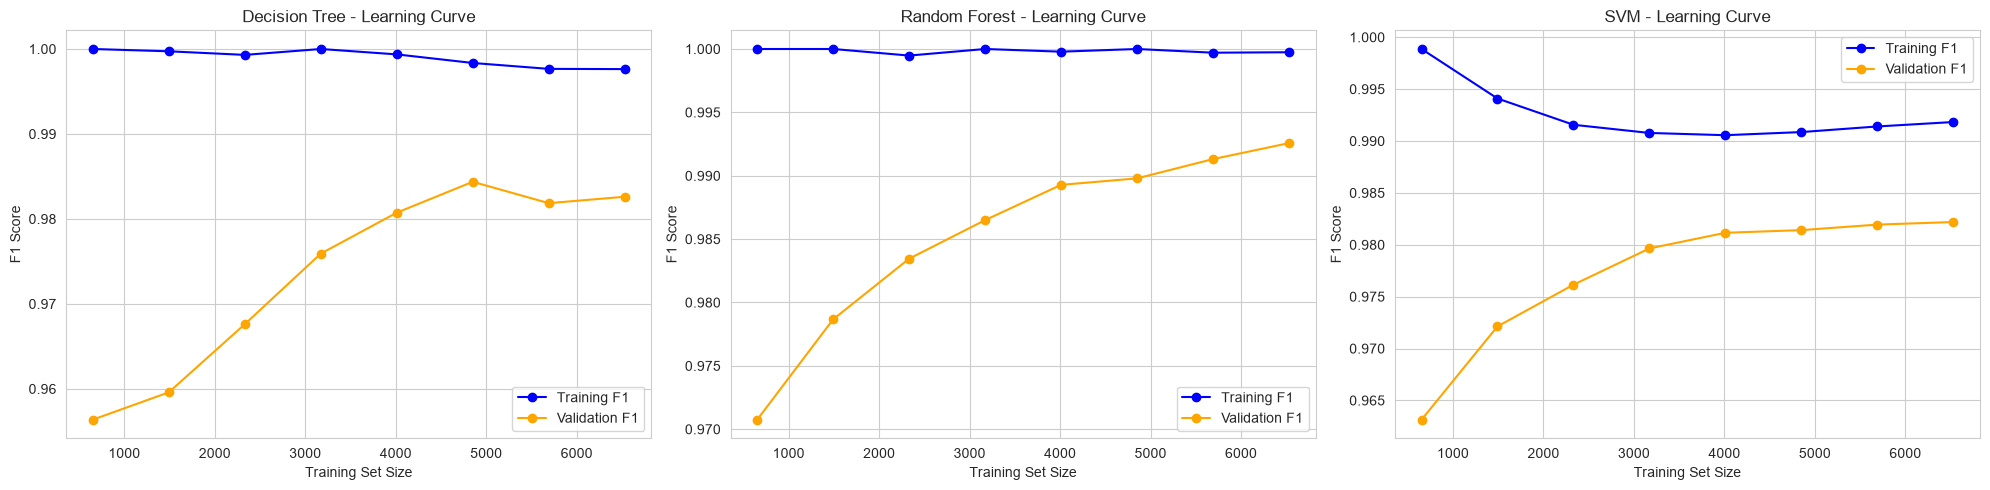


How to read this:
- If both lines are LOW and close together → UNDERFITTING (model too simple)
- If training line is HIGH but validation line is much LOWER (big gap) → OVERFITTING
- If both lines are HIGH and converge close together → GOOD FIT ✅



In [6]:
# ============================================================
# LEARNING CURVES - Overfitting/Underfitting diagnostic
# ============================================================
from sklearn.model_selection import learning_curve

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

for ax, (name, model) in zip(axes, results.items()):
    train_sizes, train_scores, val_scores = learning_curve(
        model, X_train_scaled, y_train, cv=5, scoring='f1',
        train_sizes=np.linspace(0.1, 1.0, 8), n_jobs=-1
    )
    train_mean = train_scores.mean(axis=1)
    val_mean = val_scores.mean(axis=1)

    ax.plot(train_sizes, train_mean, 'o-', label='Training F1', color='blue')
    ax.plot(train_sizes, val_mean, 'o-', label='Validation F1', color='orange')
    ax.set_title(f'{name} - Learning Curve')
    ax.set_xlabel('Training Set Size')
    ax.set_ylabel('F1 Score')
    ax.legend(loc='best')
    ax.grid(True)

plt.tight_layout()
plt.show()

print("""
How to read this:
- If both lines are LOW and close together → UNDERFITTING (model too simple)
- If training line is HIGH but validation line is much LOWER (big gap) → OVERFITTING
- If both lines are HIGH and converge close together → GOOD FIT ✅
""")